# Projeto 1 — Inteligência Artificial
## Otimização de Rotas para Distribuição de Alimentos Locais

**Unidade Curricular:** Inteligência Artificial · **Ano Letivo:** 2026/2027 · **Curso:** Engenharia de Sistemas Informáticos · **Grupo:** 06

| Nome | Número |
|---|---|
| Guilherme Araujo | 30146 |
| Rodrigo Lopes | 31525 |
| Tomas Gomes | 31501 |
| João Loureiro | 31551 |

**Repositório:** https://github.com/DevJoaoLoureiro/IA26_P01_G06

**Ficheiros do projeto**

| Ficheiro | Conteúdo |
|---|---|
| `01_eda_tiny.ipynb` | Análise exploratória do dataset final |
| `01_Project01_G06.ipynb` | Este relatório: modelação, algoritmos, resultados e análise |
| `algoritmos.py` | Classes do modelo e todos os algoritmos |
| `model.py` | Interface do modelo: leitura das instâncias, custo e viabilidade |
| `validador.py` | Validador independente das soluções (lê os CSV diretamente) |
| `test_validacao.py` | Testes com rotas escritas à mão e testes dos algoritmos |
| `data/` | Os 12 ficheiros CSV do dataset |

Todas as células deste notebook podem ser executadas por ordem, a partir da pasta do projeto. O tempo total de execução é de alguns minutos.

## 1. Resumo do Problema

A procura de alimentos locais está a crescer na União Europeia, mas os pequenos produtores têm custos de logística elevados. Este projeto desenvolve um **agente inteligente** que planeia as rotas de uma plataforma que liga produtores, clientes e um centro de recolha no distrito de Braga.

Cada artigo encomendado tem de seguir o percurso **produtor → centro de recolha (armazém) → local de entrega**, no mesmo veículo. O objetivo é **entregar todos os artigos minimizando a distância total percorrida** pelos dois veículos, respeitando:

- **Janelas temporais:** a recolha começa dentro da janela de disponibilidade do produto e a entrega dentro da janela do cliente. O veículo pode chegar mais cedo e esperar.
- **Capacidade:** a carga a bordo nunca excede a capacidade do veículo (250 kg e 300 kg).
- **Precedência:** recolha → passagem pelo armazém → entrega.
- **Tempos:** viagem (matriz de tempos), 10 min de serviço por paragem e 15 min por visita ao armazém.
- **Horizonte:** tudo termina dentro dos 2 dias de planeamento (30 e 31 de outubro de 2026).

Trata-se de uma variante do **Pickup and Delivery Problem with Time Windows (PDPTW)** com transbordo obrigatório num armazém, um problema NP-difícil. Para o resolver aplicámos as três famílias de técnicas pedidas no enunciado:

1. **Procura informada:** Greedy, Greedy Best-First Search e A*, cada um com duas heurísticas.
2. **Satisfação de restrições (CSP):** backtracking com MRV, forward checking e ordenação de valores.
3. **Procura local:** Hill Climbing e Simulated Annealing, a partir da solução inicial do Greedy.

## 2. Análise Exploratória dos Dados (resumo)

A análise completa está no notebook `01_eda_tiny.ipynb`. As conclusões com impacto na modelação foram:

| Aspeto | `data_tiny` (fase 1) | Dataset final |
|---|---|---|
| Artigos / encomendas | 23 / 10 | **80 / 25** |
| Produtores / locais de entrega | 5 / 6 | 6 / 7 |
| Capacidade dos veículos | 1444,7 + 1009,8 kg | **250 + 300 kg** |
| Peso total encomendado | muito abaixo da capacidade | **580 kg > 550 kg da frota** |
| Regras (`rules.csv`) | não existia | serviço 10 min/paragem, armazém 15 min, horizonte de 2 dias |
| Artigos inviáveis à partida | 12 (recolha terminava antes da encomenda) | **0** |

- Os dados estão completos e consistentes: não há valores em falta, duplicados ou referências inválidas. A matriz de distâncias é completa e simétrica.
- Todos os 80 artigos são servíveis **isoladamente**. A dificuldade está em servi-los **em conjunto** com dois veículos, janelas de 1,5 a 4 h e capacidade limitada.
- 20 artigos são recolhidos a 30/10 e entregues só a 31/10, ou seja, ficam a bordo durante a noite.

O dataset final não é apenas maior do que o `data_tiny`: é **qualitativamente mais difícil**. Os algoritmos que resolviam a fase 1 (procura exaustiva no espaço de estados) deixam de escalar, e isso levou às decisões das secções seguintes.

## 3. Modelação do Problema

### 3.1. Representação

As classes do modelo estão em `algoritmos.py`. O ficheiro `model.py` reúne a parte de modelação numa interface simples.

- **`Vehicle`**: identificador, capacidade (kg) e localização do centro de recolha a que pertence.
- **`Request`**: um artigo encomendado, ou seja, um par recolha/entrega, com o local de recolha (produtor do produto), o local de entrega (local da encomenda), o peso, a janela de recolha `[ready, pickup_end]` e a janela de entrega `[delivery_start, delivery_end]`. O `ready` é o máximo entre a data da encomenda e o início da disponibilidade.
- **`FleetProblem` / `Problem`**: a instância completa, com veículos, pedidos, matrizes de distância e tempo, instante inicial, tempos de serviço e fim do horizonte.
- **`State`**: o estado de **um** veículo, com localização, instante, carga, conjuntos de artigos recolhidos, que já passaram pelo armazém e entregues, rota (operações com hora de início) e distância acumulada. O estado da frota é o tuplo dos estados dos dois veículos.

**Operações (ações):** `recolha(artigo)`, `armazem` (descarrega e recarrega tudo o que está a bordo) e `entrega(artigo)`. Cada operação só é gerada se for viável: há capacidade, a janela ainda está aberta à chegada (com espera, se necessário), a precedência é respeitada e o fim fica dentro do horizonte.

**Tempo de serviço por paragem:** operações seguidas do mesmo tipo no mesmo local juntam-se à paragem em curso, sem novo tempo de serviço, se o início dessa paragem estiver na janela do artigo. Por exemplo, recolher 13 artigos no produtor 6 numa só visita custa 10 minutos, e não 130.

### 3.2. Duas representações de uma solução

1. **Espaço de estados** (usada pelo Greedy, GBFS, A* e pelo CSP cronológico): a solução constrói-se operação a operação, a partir do estado inicial (veículos no centro, nada recolhido), até todos os artigos estarem entregues.
2. **Rotas completas** (usada pelo CSP com MRV, pela reparação e pela procura local): a solução é uma lista de operações por veículo, por exemplo `[("recolha", 17), ("recolha", 60), ("armazem", 0), ("entrega", 17), ...]`. O `RouteEvaluator` simula cada rota em milissegundos, com exatamente as mesmas regras. Isto permite avaliar milhares de soluções vizinhas e inserir um artigo em qualquer posição de uma rota já construída.

### 3.3. Função de custo

$$\text{custo} = \sum_{v \in \text{veículos}} \sum_{k} d(\text{local}_{k}, \text{local}_{k+1})$$

É a distância total (km) percorrida pelos dois veículos, incluindo o regresso ao centro. Só são comparadas soluções **completas e viáveis**: uma solução parcial não tem custo comparável.

### 3.4. Restrições e verificação

| Restrição | Onde é garantida |
|---|---|
| Janela de recolha / entrega (início do serviço) | geração de ações e `RouteEvaluator` |
| Capacidade do veículo | idem |
| Recolha → armazém → entrega, no mesmo veículo | idem |
| 10 min por paragem, 15 min no armazém, espera permitida | idem |
| Horizonte de 2 dias | idem |
| Cada artigo entregue exatamente uma vez | verificação final |

Todas as soluções apresentadas são verificadas duas vezes:

1. pela simulação passo a passo do próprio modelo (`validar_rota_frota`);
2. pelo **validador independente** (`validador.py`), escrito sem reutilizar nenhuma função dos algoritmos, que lê os CSV diretamente e verifica todas as regras e a distância declarada.

### 3.5. Preparação e testes do modelo com rotas escritas à mão

In [1]:
import sys
import time
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# No Google Colab sem os ficheiros do projeto: clonar o repositório
if not Path("algoritmos.py").exists() and "google.colab" in sys.modules:
    subprocess.run(["git", "clone", "https://github.com/DevJoaoLoureiro/IA26_P01_G06.git"],
                   check=True)
    import os
    os.chdir("IA26_P01_G06")
sys.path.insert(0, ".")

import algoritmos as A
import model
import validador

PASTA = Path("data")
problema = A.load_fleet_problem(PASTA)
print("Veículos:", [(v.vehicle_id, v.capacity_kg) for v in problema.vehicles])
print("Artigos:", len(problema.requests), "| rejeitados à partida:", len(problema.rejected))
print("Início:", problema.start_time, "| fim do horizonte:", problema.horizon_end)
print("Serviço por paragem:", problema.stop_service_min, "min | armazém:",
      problema.warehouse_handling_min, "min")

Veículos: [(1, 250.0), (2, 300.0)]
Artigos: 80 | rejeitados à partida: 0
Início: 2026-10-30 06:45:00 | fim do horizonte: 2026-11-01 00:00:00
Serviço por paragem: 10.0 min | armazém: 15.0 min


In [2]:
# Nomes legíveis das localizações e funções de apoio à apresentação
locais = pd.read_csv(PASTA / "locations.csv").set_index("location_id")
nome_local = lambda loc: f"{loc} {locais.loc[loc, 'name']}"


def tabela_rota(rota):
    """Agrupa as operações de uma rota em paragens: uma linha por paragem."""
    linhas = []
    for tipo, artigo, loc, inicio in rota:
        hora = pd.Timestamp(inicio).strftime("%d/%m %H:%M")
        if (linhas and tipo in ("recolha", "entrega") and linhas[-1]["operação"] == tipo
                and linhas[-1]["local"] == nome_local(loc) and linhas[-1]["início"] == hora):
            linhas[-1]["artigos"] += f", {artigo}"
            continue
        linhas.append({"início": hora, "operação": tipo, "local": nome_local(loc),
                       "artigos": str(artigo) if tipo in ("recolha", "entrega") else ""})
    return pd.DataFrame(linhas)


def problema_com(ids):
    """Subproblema apenas com os artigos indicados."""
    p = A.load_fleet_problem(PASTA)
    p.requests = [r for r in p.requests if r.item_id in ids]
    return p


# Rota escrita à mão: artigos 17 e 60 (produtor 4 -> Restaurante 3), no veículo 1
p = problema_com({17, 60})
rota = [("recolha", 17), ("recolha", 60), ("armazem", 0), ("entrega", 17), ("entrega", 60)]
print("Viável:", model.viavel(p, [rota, []]), "| custo:", model.custo(p, [rota, []]), "km")
display(tabela_rota(model.simular(p, [rota, []]).routes[1]))

Viável: True | custo: 36.32 km


,início,operação,local,artigos
0,30/10 06:45,recolha,4 Courela Carvalho,17
1,30/10 07:15,recolha,4 Courela Carvalho,60
2,30/10 07:25,armazem,7 Centro de Recolha 1,
3,30/10 11:15,entrega,10 Restaurante 3,"17, 60"
4,30/10 11:49,regresso,7 Centro de Recolha 1,


In [3]:
# Rotas inviáveis escritas à mão: o modelo tem de as rejeitar
testes = {
    "entrega sem passar pelo armazém": ([("recolha", 17), ("entrega", 17)], {17}),
    "entrega antes da recolha": ([("armazem", 0), ("entrega", 17)], {17}),
    "recolha do 60 depois das 09:00 (2 → 1 → 60)": ([("recolha", 2), ("recolha", 1), ("recolha", 60)], {1, 2, 60}),
    "artigo 60 esquecido": ([("recolha", 17), ("armazem", 0), ("entrega", 17)], {17, 60}),
}
display(pd.DataFrame([{"rota": nome,
                       "viável segundo o modelo": model.viavel(problema_com(ids), [r, []],
                                                               todos_os_artigos=(nome == "artigo 60 esquecido"))}
                      for nome, (r, ids) in testes.items()]))

,rota,viável segundo o modelo
0,entrega sem passar pelo armazém,False
1,entrega antes da recolha,False
2,recolha do 60 depois das 09:00 (2 → 1 → 60),False
3,artigo 60 esquecido,False


A rota manual dos artigos 17 e 60 mostra as regras em ação:

1. O artigo 17 é recolhido às 06:45.
2. O artigo 60 só fica disponível às 07:15, por isso o veículo espera e faz uma segunda paragem.
3. A passagem pelo armazém é às 07:25 (o produtor 4 fica no mesmo local do centro, por isso a viagem é de 0 km).
4. As duas entregas fazem-se **na mesma paragem** às 11:15, quando abre a janela do cliente.

O custo, 2 × 18,16 = 36,32 km, coincide com o cálculo à mão. Todas as rotas inviáveis são rejeitadas.

O ficheiro `test_validacao.py` contém estes e outros testes, incluindo um de capacidade em que os veículos têm só 3 kg. Podem ser corridos com `python test_validacao.py`.

## 4. Procura Informada

### 4.1. Heurísticas

| Algoritmo | Avaliação | H1 | H2 |
|---|---|---|---|
| **Greedy construtivo** | escolhe uma ação em cada passo, sem retroceder | operação que **termina mais cedo** (inclui esperas); em empate, a mais curta | operação com **menor folga temporal** (urgência) |
| **GBFS** | fronteira ordenada só por $h(n)$ | $h$ = distância à próxima operação viável mais próxima | $h$ = menor folga temporal das próximas operações |
| **A\*** | $f(n) = g(n) + h(n)$, com $g$ = km percorridos | $h = 0$ (custo uniforme) | $h$ = distância à próxima operação viável mais próxima |

A heurística H2 do A* é **admissível**: enquanto houver artigos por entregar, algum veículo tem de fazer pelo menos mais uma deslocação até uma operação viável. Por isso, a menor dessas distâncias nunca sobrestima o custo restante. A H1 ($h = 0$) é trivialmente admissível, e com ela o A* é uma procura de custo uniforme, **ótima** quando termina.

No GBFS e no A* usamos ainda **forward checking**: um sucessor é podado se algum artigo pendente já não puder ser entregue, nem no caso mais otimista (sem os outros artigos e com viagem direta). Como esta poda só elimina estados sem solução, não compromete a otimalidade do A*.

A primeira versão do Greedy H1 escolhia apenas a operação mais curta em km. Isso ignorava as esperas: a carrinha ficava parada à espera de artigos do dia seguinte e falhava as entregas do próprio dia. Mesmo com o tempo de serviço já corrigido, esse critério só entregava 7 dos 80 artigos. Mudá-lo para "termina mais cedo" fez o Greedy H1 passar para 71.

### 4.2. Greedy construtivo na instância completa (80 artigos)

In [4]:
resultados = {}  # todos os resultados finais, para a comparação da secção 7

for h in (1, 2):
    r = A.fleet_greedy(problema, h)
    resultados[f"Greedy H{h}"] = r
    print(f"Greedy H{h}: {r.delivered}/{r.total} artigos entregues, {r.distance_km:.1f} km, "
          f"{r.expanded} passos, {r.runtime_s:.2f} s — {r.message or 'solução completa'}")

Greedy H1: 71/80 artigos entregues, 1191.1 km, 164 passos, 0.14 s — Sem próximas ações válidas; solução parcial
Greedy H2: 7/80 artigos entregues, 988.9 km, 48 passos, 0.04 s — Sem próximas ações válidas; solução parcial


O Greedy é instantâneo, mas **míope**: nunca reconsidera uma decisão. O H1 entrega 71 dos 80 artigos. Os 9 que falham são recolhidos cedo demais ou ficam sem tempo para a viagem ao armazém e ao cliente. O H2 escolhe sempre a operação mais urgente, independentemente da distância, e por isso atravessa o distrito de um lado para o outro e esgota as janelas ao fim de 7 entregas.

Uma solução parcial não serve de ponto de partida para a procura local. Por isso acrescentámos uma fase de **reparação** (secção 4.4).

### 4.3. GBFS e A*: escalabilidade da procura no espaço de estados

O GBFS e o A* exploram o espaço de estados de forma sistemática, com uma fronteira de prioridades. Como esse espaço cresce exponencialmente com o número de artigos, avaliámo-los em instâncias crescentes: os 3, 5 e 8 primeiros artigos do dataset, com um limite de 20 000 expansões.

In [5]:
linhas, rotas_astar = [], {}
for n in (3, 5, 8):
    for nome, funcao in [("GBFS H1", lambda p: A.fleet_gbfs(p, 1, 20000, True)),
                         ("GBFS H2", lambda p: A.fleet_gbfs(p, 2, 20000, True)),
                         ("A* H1", lambda p: A.fleet_astar(p, 1, 20000, True)),
                         ("A* H2", lambda p: A.fleet_astar(p, 2, 20000, True))]:
        p = A.load_fleet_problem(PASTA)
        p.requests = p.requests[:n]
        r = funcao(p)
        valido = (validador.validar(PASTA, r.routes, r.distance_km,
                                    {q.item_id for q in p.requests})[0] if r.feasible else None)
        linhas.append({"artigos": n, "algoritmo": nome, "completa": r.feasible,
                       "entregues": r.delivered, "distância_km": round(r.distance_km, 2) if r.feasible else None,
                       "nós_expandidos": r.expanded, "tempo_s": round(r.runtime_s, 2),
                       "validada": valido})
        if r.feasible and nome.startswith("A*"):
            rotas_astar[(n, nome)] = r
procura = pd.DataFrame(linhas)
procura

,artigos,algoritmo,completa,entregues,distância_km,nós_expandidos,tempo_s,validada
0,3,GBFS H1,True,3,287.35,40,0.01,True
1,3,GBFS H2,True,3,381.59,268,0.05,True
2,3,A* H1,True,3,229.87,321,0.04,True
3,3,A* H2,True,3,229.87,283,0.06,True
4,5,GBFS H1,True,5,362.67,5481,1.88,True
5,5,GBFS H2,True,5,466.16,14840,5.21,True
6,5,A* H1,True,5,248.32,13207,3.36,True
7,5,A* H2,True,5,248.32,11901,4.98,True
8,8,GBFS H1,False,4,NaN,20000,19.18,None
9,8,GBFS H2,False,7,NaN,20000,13.00,None


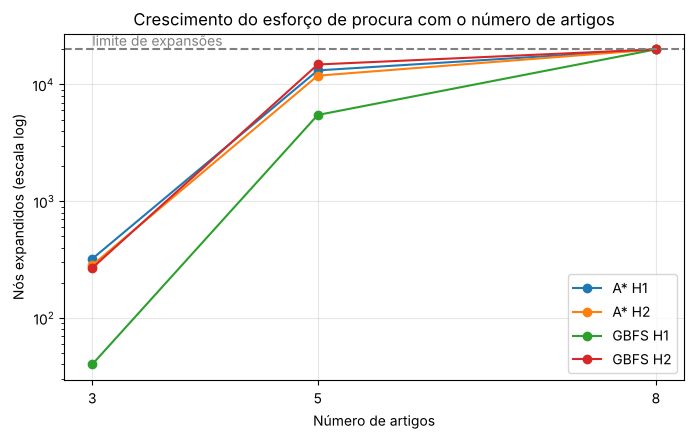

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, grupo in procura.groupby("algoritmo"):
    ax.plot(grupo["artigos"], grupo["nós_expandidos"], marker="o", label=nome)
ax.axhline(20000, ls="--", color="gray")
ax.text(3, 21500, "limite de expansões", color="gray")
ax.set_yscale("log")
ax.set_xticks([3, 5, 8])
ax.set_xlabel("Número de artigos")
ax.set_ylabel("Nós expandidos (escala log)")
ax.set_title("Crescimento do esforço de procura com o número de artigos")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Rotas ótimas para os 5 primeiros artigos** (A* H2). O A* com H1 (custo uniforme) chega à mesma distância, por isso esta solução é **ótima** para este subproblema. Repare-se que a solução ótima usa só o veículo 1, que recolhe os 5 artigos numa volta e os entrega em duas paragens; o veículo 2 não sai do centro. Usar o segundo veículo só acrescentaria deslocações.

In [7]:
r5 = rotas_astar[(5, "A* H2")]
print(f"Distância total: {r5.distance_km:.2f} km | nós expandidos: {r5.expanded}")
for vid, rota in r5.routes.items():
    print(f"\nVeículo {vid}:")
    display(tabela_rota(rota))

Distância total: 248.32 km | nós expandidos: 11901

Veículo 1:


,início,operação,local,artigos
0,30/10 07:00,recolha,4 Courela Carvalho,4
1,30/10 07:48,recolha,3 Horta Morais,1
2,30/10 08:45,recolha,2 Campos Leite,5
3,30/10 09:42,recolha,6 Campos Oliveira,"2, 3"
4,30/10 10:24,armazem,7 Centro de Recolha 1,
5,30/10 12:30,entrega,12 Restaurante 5,"1, 2"
6,30/10 14:02,entrega,11 Loja 4,"3, 4, 5"
7,30/10 14:38,regresso,7 Centro de Recolha 1,



Veículo 2:


,início,operação,local,artigos
0,30/10 06:45,regresso,7 Centro de Recolha 1,


#### 4.3.1. Análise da procura no espaço de estados

- **Até 5 artigos**, as quatro configurações encontram soluções completas. Os dois A* chegam à mesma distância, que é a **ótima**: o A* H1 (custo uniforme) é ótimo, e a H2, por ser admissível, também o é.
- **A H2 reduz o esforço do A*** face à H1: expande menos nós para a mesma solução ótima (283 contra 321 com 3 artigos; 11 901 contra 13 207 com 5). É o efeito esperado de uma heurística admissível mais informativa. Em tempo, o ganho perde-se, porque calcular a H2 obriga a gerar as operações viáveis de cada estado.
- **O GBFS** não garante a melhor solução: com 3 e 5 artigos encontra rotas 25% a 88% mais longas do que o ótimo. O GBFS H1, guiado pela distância, é o que precisa de menos nós (40 e 5481). O GBFS H2, guiado só pela urgência, chega a expandir mais nós do que o próprio A*, porque a folga temporal não diz nada sobre a proximidade da solução.
- **Com 8 artigos**, nenhuma configuração termina dentro das 20 000 expansões. O número de nós cresce de forma **exponencial**: cada estado tem até $2 \times (\text{artigos pendentes} + 1)$ sucessores (dois veículos e cada operação possível), e o estado inclui o instante de cada veículo, o que reduz a deteção de estados repetidos.

Com 80 artigos, uma procura sistemática no espaço de estados é impraticável. É uma limitação intrínseca do problema, não da implementação. Por isso usamos estes algoritmos para **estudar** o problema em instâncias pequenas (incluindo o cálculo de ótimos de referência) e recorremos a outras formulações para a instância completa.

### 4.4. Greedy com reparação por inserção mais barata

Para obter uma **solução completa** a partir do Greedy, os artigos que este não entregou são retirados das rotas e **reinseridos um a um**, por ordem de prazo de entrega. Cada artigo vai para a posição viável que menos aumenta a distância (*cheapest insertion*), em qualquer um dos veículos. A recolha entra na posição $i$ e a entrega na posição $j \ge i$; se não houver passagem pelo armazém entre as duas, é acrescentada uma imediatamente antes da entrega. Esta é a heurística construtiva clássica dos problemas de recolha e entrega.

In [8]:
for h in (1, 2):
    r = A.fleet_greedy_repair(problema, h)
    resultados[f"Greedy H{h} + reparação"] = r
    print(f"Greedy H{h} + reparação: {r.delivered}/{r.total} entregues, {r.distance_km:.2f} km, "
          f"{r.runtime_s:.2f} s — {r.message}")

Greedy H1 + reparação: 80/80 entregues, 1223.74 km, 0.46 s — greedy entregou 71/80; reparados 9
Greedy H2 + reparação: 79/80 entregues, 1230.91 km, 2.04 s — greedy entregou 7/80; reparados 72; sem inserção viável: [38]


Com a reparação, o **Greedy H1 passa a uma solução completa** com os 80 artigos, em menos de um segundo. Esta é a solução inicial da procura local (secção 6).

O Greedy H2 parte de rotas muito más (só 7 artigos entregues), e a reparação tem de inserir 72 artigos em rotas mal desenhadas. Chega a 79/80: o artigo que sobra já não cabe em nenhuma posição viável. A qualidade da solução construtiva inicial importa.

## 5. Satisfação de Restrições (CSP)

### 5.1. Formulação

Na fase 1, o CSP era resolvido por *backtracking* **cronológico**: em cada passo escolhia a próxima operação de um veículo e recuava quando ficava bloqueado. Essa formulação funciona com poucos artigos, mas não com 80. Uma má decisão tomada cedo (por exemplo, às 08:00) só é detetada muitos passos depois (às 14:00), e o backtracking tem de desfazer todas as decisões intermédias antes de chegar à que causou o problema.

Reformulámos o CSP de modo a que cada **variável** seja um artigo:

- **Variáveis:** $X_i$, uma por artigo (80 variáveis).
- **Domínio de $X_i$:** as inserções viáveis do par recolha/entrega do artigo nas rotas atuais, ou seja, o veículo, a posição da recolha e a posição da entrega (com passagem pelo armazém entre elas).
- **Restrições:** janelas de recolha e de entrega, capacidade, precedência recolha → armazém → entrega no mesmo veículo, tempo de serviço por paragem e horizonte. São verificadas pelo `RouteEvaluator` em cada atribuição.

**Heurísticas do backtracking:**

- **MRV (*Minimum Remaining Values*):** atribui primeiro o artigo com menos inserções viáveis, ou seja, o mais restringido. Em caso de empate, o de prazo de entrega mais cedo.
- **Ordenação de valores:** tenta primeiro as inserções que menos aumentam a distância. Só as 4 melhores são consideradas em cada nível, para limitar a ramificação.
- **Forward checking:** depois de cada atribuição recalcula os domínios dos artigos por atribuir. Se algum ficar vazio, recua de imediato, sem esperar pelo fim da rota.

Para o MRV basta distinguir domínios pequenos, por isso a contagem do domínio pára às 25 inserções e é guardada em cache por rota. Isto torna o forward checking barato.

In [9]:
r = A.fleet_csp_cronologico(problema, max_nodes=4000)
resultados["CSP cronológico"] = r
print(f"CSP cronológico (fase 1): completa={r.feasible}, entregues={r.delivered}/{r.total}, "
      f"nós={r.expanded}, {r.runtime_s:.2f} s — {r.message}")

r = A.fleet_csp(problema)
resultados["CSP (MRV + FC)"] = r
print(f"CSP com MRV e forward checking: completa={r.feasible}, entregues={r.delivered}/{r.total}, "
      f"{r.distance_km:.2f} km, nós={r.expanded}, {r.runtime_s:.1f} s — {r.message}")

CSP cronológico (fase 1): completa=False, entregues=0/80, nós=4000, 0.46 s — Sem solução completa ou limite atingido; backtracks=4000
CSP com MRV e forward checking: completa=True, entregues=80/80, 1389.51 km, nós=267, 15.8 s — backtracks=187


### 5.2. Análise do CSP

- O **CSP cronológico** esgota as 4000 tentativas sem encontrar solução completa. Na tabela aparece com 0 entregas porque só devolve soluções completas. É o comportamento que impedia a fase 1 de escalar.
- O **CSP com MRV e forward checking** encontra uma **atribuição completa e viável dos 80 artigos**. O número de backtracks mostra que a procura teve de corrigir várias decisões, mas o forward checking detetou cada problema assim que surgiu.
- A distância é maior do que a do Greedy com reparação. Isto é esperado: o objetivo do CSP é a **viabilidade**, e a ordem MRV atribui primeiro os artigos mais restringidos, não os que dão rotas mais curtas. A solução do CSP serve também como ponto de partida alternativo para a procura local (secção 6.3).

## 6. Procura Local

Ambos os métodos partem de uma solução **completa e viável** e só aceitam vizinhos viáveis, pelo que a viabilidade é mantida em todas as iterações.

### 6.1. Hill Climbing

- **Vizinhança *relocate*:** retirar um artigo (recolha e entrega) da rota e reinseri-lo na melhor posição viável, no mesmo veículo ou no outro. Há 80 vizinhos por iteração, um por artigo.
- **Estratégia:** subida mais íngreme. Em cada iteração aplica-se o melhor vizinho; o algoritmo pára quando nenhum vizinho reduz a distância (ótimo local).
- **Solução inicial:** Greedy H1 + reparação, como pede o enunciado.

In [10]:
inicial = resultados["Greedy H1 + reparação"]
hc = A.fleet_hill_climbing(problema, inicial)
resultados["Hill Climbing"] = hc
print(f"Hill Climbing: {hc.history[0]:.2f} km -> {hc.distance_km:.2f} km "
      f"({(1 - hc.distance_km / hc.history[0]) * 100:.1f}% menos) em {hc.expanded} iterações, "
      f"{hc.runtime_s:.1f} s")
print("Custo por iteração:", [round(c, 2) for c in hc.history])

Hill Climbing: 1223.74 km -> 1156.09 km (5.5% menos) em 5 iterações, 25.1 s
Custo por iteração: [1223.74, 1187.63, 1169.13, 1159.11, 1158.8, 1156.09]


### 6.2. Simulated Annealing

- **Vizinhança "destruir e reconstruir":** retira 1 a 3 artigos ao acaso e reinsere-os, por ordem aleatória, na melhor posição viável. É uma vizinhança mais ampla do que a do Hill Climbing.
- **Aceitação:** um vizinho melhor é sempre aceite; um pior é aceite com probabilidade $e^{-\Delta/T}$. Isto permite sair de ótimos locais.
- **Arrefecimento geométrico:** $T \leftarrow 0{,}995 \cdot T$, com $T_0 = 10$ km e 800 iterações. A semente é fixa (42), para os resultados serem reprodutíveis.
- **Solução inicial:** a mesma do Hill Climbing.

In [11]:
sa = A.fleet_simulated_annealing(problema, inicial, iterations=800, initial_temp=10.0,
                                 cooling=0.995, seed=42)
resultados["Simulated Annealing"] = sa
print(f"Simulated Annealing: {sa.history[0]:.2f} km -> {sa.distance_km:.2f} km "
      f"({(1 - sa.distance_km / sa.history[0]) * 100:.1f}% menos), {sa.runtime_s:.1f} s — {sa.message}")

Simulated Annealing: 1223.74 km -> 1154.20 km (5.7% menos), 87.2 s — inicial=1223.74 km; aceites=783


### 6.3. Hill Climbing a partir da solução do CSP

Para avaliar a sensibilidade da procura local ao ponto de partida, aplicámos também o Hill Climbing à solução do CSP.

In [12]:
hc_csp = A.fleet_hill_climbing(problema, resultados["CSP (MRV + FC)"])
resultados["CSP + Hill Climbing"] = hc_csp
print(f"CSP + Hill Climbing: {hc_csp.history[0]:.2f} km -> {hc_csp.distance_km:.2f} km "
      f"em {hc_csp.expanded} iterações, {hc_csp.runtime_s:.1f} s")

CSP + Hill Climbing: 1389.51 km -> 1295.31 km em 1 iterações, 6.9 s


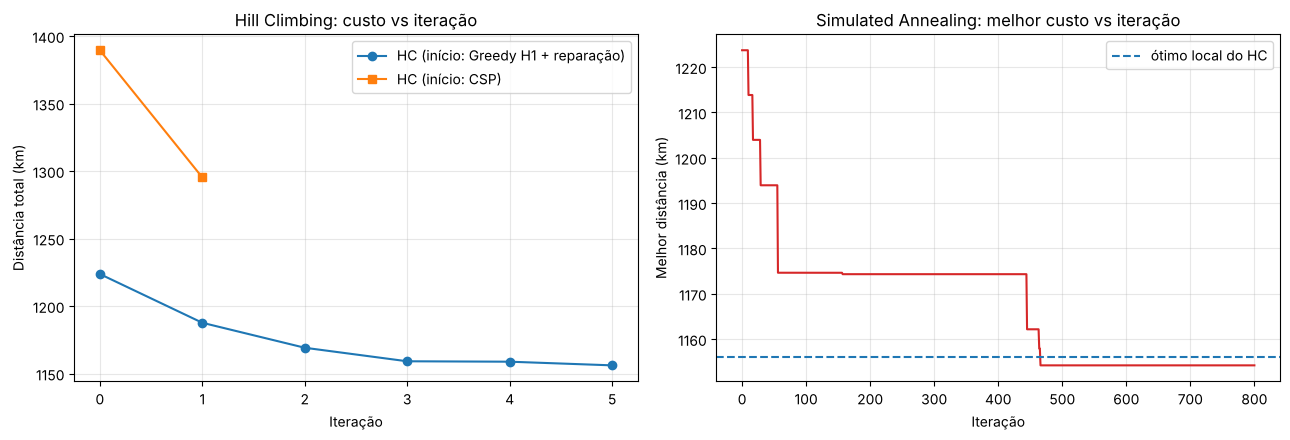

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(hc.history, marker="o", label="HC (início: Greedy H1 + reparação)")
ax[0].plot(hc_csp.history, marker="s", label="HC (início: CSP)")
ax[0].set_title("Hill Climbing: custo vs iteração")
ax[0].set_xlabel("Iteração")
ax[0].set_ylabel("Distância total (km)")
ax[0].grid(alpha=0.3)
ax[0].legend()
ax[1].plot(sa.history, color="tab:red")
ax[1].axhline(hc.distance_km, ls="--", color="tab:blue", label="ótimo local do HC")
ax[1].set_title("Simulated Annealing: melhor custo vs iteração")
ax[1].set_xlabel("Iteração")
ax[1].set_ylabel("Melhor distância (km)")
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.show()

### 6.4. Análise da procura local

- O **Hill Climbing** converge em poucas iterações. As primeiras dão os maiores ganhos (é aí que se corrigem as inserções menos eficientes da reparação) e depois os ganhos diminuem até ao ótimo local.
- O **Simulated Annealing** chega a uma solução ligeiramente melhor do que o Hill Climbing. A vizinhança "destruir e reconstruir" e a aceitação de pioras temporárias permitem escapar ao ótimo local onde o HC pára. Em contrapartida, demora mais tempo e depende de parâmetros ($T_0$, arrefecimento, número de iterações) e da semente aleatória.
- **O ponto de partida conta:** a partir do CSP, o Hill Climbing faz uma única mudança, que poupa 94 km (de 1389,5 para 1295,3 km), e para. A solução do CSP tem uma estrutura diferente (menos paragens, mas trajetos mais longos entre elas), e mover um artigo de cada vez não chega para a reorganizar: qualquer mudança isolada viola alguma janela ou aumenta a distância. Os métodos de subida pura ficam presos ao ótimo local mais próximo do ponto de partida.
- No SA, a maioria dos vizinhos é **neutra** (o artigo volta à mesma posição, com $\Delta = 0$), o que explica as 783 aceitações em 800 iterações. As melhorias reais concentram-se em poucos saltos, visíveis no gráfico em escada.

## 7. Resultados e Comparação

### 7.1. Tabela comparativa (80 artigos, 2 veículos)

Todas as soluções completas foram auditadas pelo **validador independente**.

In [14]:
linhas = []
for nome, r in resultados.items():
    if r.feasible:
        valido, erros, km = validador.validar(PASTA, r.routes, r.distance_km)
    else:
        valido, erros, km = None, [], None
    linhas.append({"algoritmo": nome, "completa": r.feasible,
                   "entregues": f"{r.delivered}/{r.total}",
                   "distância_km": round(r.distance_km, 2) if r.feasible else None,
                   "tempo_s": round(r.runtime_s, 2),
                   "nós / passos / iterações": r.expanded,
                   "validador independente": "válida" if valido else ("—" if valido is None else erros[0])})
comparacao = pd.DataFrame(linhas)
comparacao

,algoritmo,completa,entregues,distância_km,tempo_s,nós / passos / iterações,validador independente
0,Greedy H1,False,71/80,NaN,0.14,164,—
1,Greedy H2,False,7/80,NaN,0.04,48,—
2,Greedy H1 + reparação,True,80/80,1223.74,0.46,164,válida
3,Greedy H2 + reparação,False,79/80,NaN,2.04,0,—
4,CSP cronológico,False,0/80,NaN,0.46,4000,—
5,CSP (MRV + FC),True,80/80,1389.51,15.79,267,válida
6,Hill Climbing,True,80/80,1156.09,25.13,5,válida
7,Simulated Annealing,True,80/80,1154.20,87.22,800,válida
8,CSP + Hill Climbing,True,80/80,1295.31,6.89,1,válida


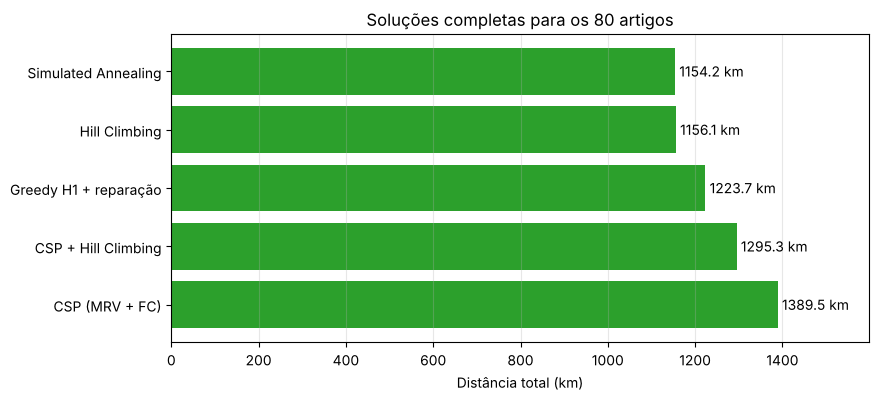

In [15]:
completas = comparacao[comparacao["completa"]].sort_values("distância_km")
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(completas["algoritmo"], completas["distância_km"], color="tab:green")
ax.bar_label(barras, fmt="%.1f km", padding=3)
ax.set_xlim(0, completas["distância_km"].max() * 1.15)
ax.invert_yaxis()
ax.set_xlabel("Distância total (km)")
ax.set_title("Soluções completas para os 80 artigos")
ax.grid(axis="x", alpha=0.3)
plt.show()

### 7.2. Melhor solução encontrada

In [16]:
melhor_nome = completas.iloc[0]["algoritmo"]
melhor = resultados[melhor_nome]
print(f"Melhor solução: {melhor_nome} — {melhor.distance_km:.2f} km, {melhor.delivered} artigos")
for vid, rota in melhor.routes.items():
    km_v = sum(0 if a == b else problema.distance[(a, b)]
               for a, b in zip([locais.index[locais.location_type == "collection_center"][0]]
                               + [op[2] for op in rota], [op[2] for op in rota]))
    t = tabela_rota(rota)
    print(f"\nVeículo {vid}: {len(t)} paragens, {sum(op[0] == 'armazem' for op in rota)} "
          f"passagens pelo armazém, {km_v:.1f} km")
    display(t)

Melhor solução: Simulated Annealing — 1154.20 km, 80 artigos

Veículo 1: 27 paragens, 2 passagens pelo armazém, 548.8 km


,início,operação,local,artigos
0,30/10 06:45,recolha,4 Courela Carvalho,"17, 45"
1,30/10 07:15,recolha,4 Courela Carvalho,"78, 4, 60"
2,30/10 08:15,recolha,6 Campos Oliveira,"15, 59, 55, 3, 48, 54, 53, 77, 19, 36, 50, 2"
3,30/10 08:45,recolha,1 Hortas Valente,"58, 16, 62, 34, 80, 13"
4,30/10 10:26,recolha,5 Horta Antunes,"49, 61, 52, 31, 14, 35, 79, 30"
5,30/10 11:28,armazem,7 Centro de Recolha 1,
6,30/10 12:02,entrega,13 Loja 6,49
7,30/10 12:12,entrega,8 Casa 1,48
8,30/10 12:22,entrega,13 Loja 6,50
9,30/10 12:37,entrega,10 Restaurante 3,"59, 55, 17, 58, 19, 60"



Veículo 2: 26 paragens, 2 passagens pelo armazém, 605.4 km


,início,operação,local,artigos
0,30/10 07:15,recolha,4 Courela Carvalho,46
1,30/10 07:56,recolha,6 Campos Oliveira,73
2,30/10 08:45,recolha,1 Hortas Valente,72
3,30/10 09:30,recolha,2 Campos Leite,"29, 18, 5, 47, 56, 20"
4,30/10 10:14,recolha,3 Horta Morais,"28, 51, 57, 1, 44, 37"
5,30/10 11:03,armazem,7 Centro de Recolha 1,
6,30/10 11:37,entrega,13 Loja 6,51
7,30/10 11:47,entrega,8 Casa 1,47
8,30/10 12:02,entrega,10 Restaurante 3,"18, 57, 56, 20"
9,30/10 13:13,entrega,12 Restaurante 5,"28, 1, 29"


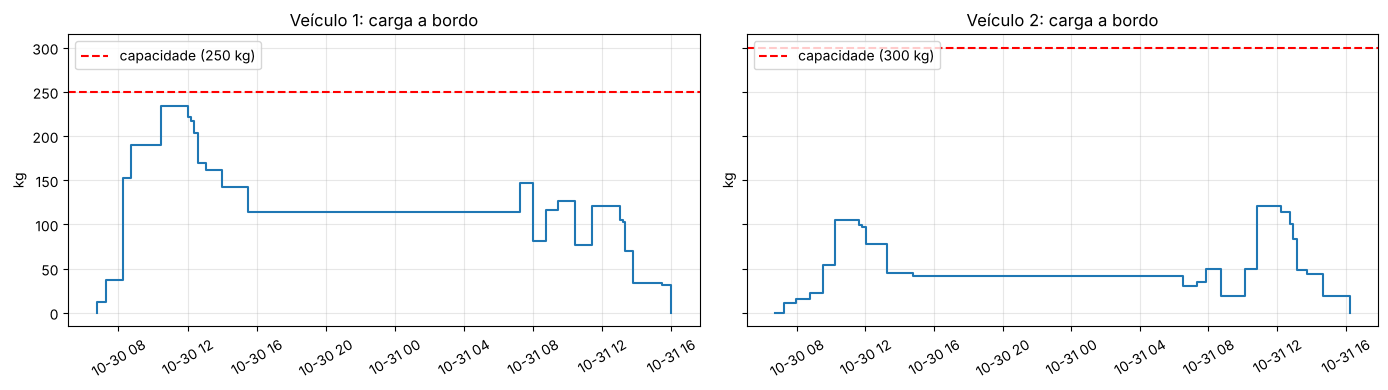

In [17]:
# Carga a bordo ao longo do tempo (verificação visual da capacidade)
pesos = {r.item_id: r.weight for r in problema.requests}
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, v in zip(ax, problema.vehicles):
    tempos, cargas, carga = [problema.start_time], [0.0], 0.0
    for tipo, artigo, loc, inicio in melhor.routes[v.vehicle_id]:
        if tipo in ("recolha", "entrega"):
            carga += pesos[artigo] if tipo == "recolha" else -pesos[artigo]
            tempos.append(pd.Timestamp(inicio))
            cargas.append(carga)
    a.step(tempos, cargas, where="post")
    a.axhline(v.capacity_kg, color="red", ls="--", label=f"capacidade ({v.capacity_kg:.0f} kg)")
    a.set_title(f"Veículo {v.vehicle_id}: carga a bordo")
    a.set_ylabel("kg")
    a.grid(alpha=0.3)
    a.legend(loc="upper left")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

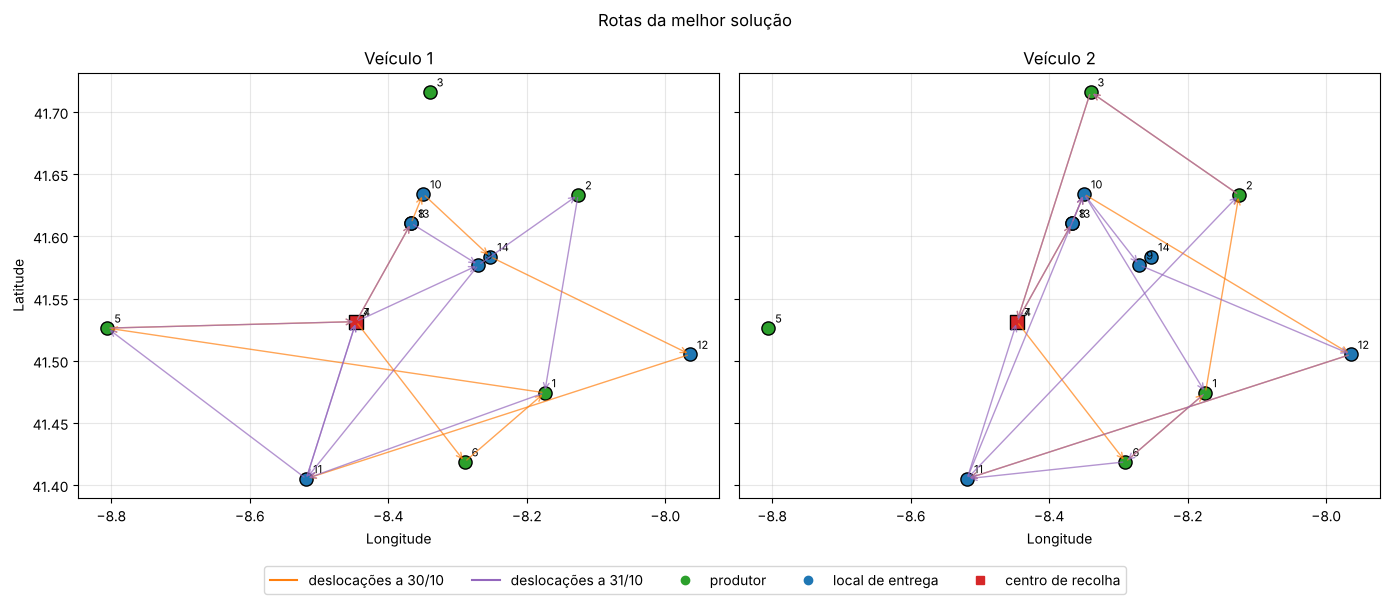

In [18]:
# Mapa das rotas da melhor solução, por veículo e por dia
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
cores_dia = {30: "tab:orange", 31: "tab:purple"}
centro = int(locais.index[locais.location_type == "collection_center"][0])
for a, v in zip(ax, problema.vehicles):
    for tipo, cor, marca in [("producer", "tab:green", "o"), ("delivery_location", "tab:blue", "o"),
                             ("collection_center", "tab:red", "s")]:
        g = locais[locais.location_type == tipo]
        a.scatter(g.longitude, g.latitude, c=cor, marker=marca, s=90, edgecolors="black", zorder=3)
    for loc_id, l in locais.iterrows():
        a.annotate(str(loc_id), (l.longitude, l.latitude), xytext=(5, 4),
                   textcoords="offset points", fontsize=8)
    anterior = centro
    for tipo, artigo, loc, inicio in melhor.routes[v.vehicle_id]:
        if loc != anterior:
            dia = pd.Timestamp(inicio).day
            p0, p1 = locais.loc[anterior], locais.loc[loc]
            a.annotate("", xy=(p1.longitude, p1.latitude), xytext=(p0.longitude, p0.latitude),
                       arrowprops=dict(arrowstyle="->", color=cores_dia.get(dia, "gray"), alpha=0.7))
        anterior = loc
    a.set_title(f"Veículo {v.vehicle_id}")
    a.set_xlabel("Longitude")
    a.grid(alpha=0.3)
ax[0].set_ylabel("Latitude")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color="tab:orange", label="deslocações a 30/10"),
                    Line2D([], [], color="tab:purple", label="deslocações a 31/10"),
                    Line2D([], [], marker="o", ls="", color="tab:green", label="produtor"),
                    Line2D([], [], marker="o", ls="", color="tab:blue", label="local de entrega"),
                    Line2D([], [], marker="s", ls="", color="tab:red", label="centro de recolha")],
           loc="lower center", ncol=5)
fig.suptitle("Rotas da melhor solução")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### 7.3. Análise crítica dos resultados

**Qualidade das soluções.** A melhor solução, do **Simulated Annealing, tem 1154,20 km**. Entrega os 80 artigos com 2 passagens pelo armazém por veículo (uma por dia). O Hill Climbing fica a menos de 2 km (1156,09 km) em menos de um terço do tempo. Face à solução inicial do Greedy com reparação (1223,74 km), a procura local poupa cerca de 70 km (5,7%).

O gráfico de carga confirma que a capacidade nunca é excedida: o veículo 1 chega a cerca de 234 kg dos 250 kg na manhã de 30/10. O mapa mostra a estrutura esperada pela EDA: uma volta de recolhas de manhã, a passagem pelo armazém e uma volta de entregas, repetida em cada dia.

**Comparação dos algoritmos**

| | Procura informada (Greedy, GBFS, A*) | CSP (MRV + FC) | Procura local (HC, SA) |
|---|---|---|---|
| Objetivo | construir uma solução / encontrar a ótima | encontrar uma solução viável | melhorar uma solução viável |
| Resultado com 80 artigos | Greedy H1 + reparação: completa | completa | as melhores soluções |
| Garantia | A* ótimo (só até 5 artigos) | completo, se não houver limite | nenhuma (ótimo local) |
| Tempo | Greedy < 1 s; A* exponencial | ~16 s | 7–90 s |

**Porque é que os algoritmos que resolviam a fase 1 não chegam aos 80 artigos?** O professor observou que, se o algoritmo funciona para 5 artigos, deveria funcionar para 80. Isso é verdade para a **correção** do algoritmo, mas não para o seu **custo**. O A* e o CSP cronológico estão corretos (com 3 e 5 artigos dão soluções ótimas e validadas), mas exploram um espaço que cresce exponencialmente: passar de 5 para 8 artigos já esgota 20 000 expansões. Para 80 artigos, o problema exige formulações que escalem, e foi isso que fizemos:

1. **Corrigir o modelo:** contar o serviço por paragem e não por artigo (secção 3.1). Este foi o erro que tornava a instância artificialmente impossível.
2. **Melhorar a heurística do Greedy:** escolher a operação que termina mais cedo (de 7 para 71 artigos entregues).
3. **Reparar por inserção** os artigos em falta (de 71 para 80).
4. **Reformular o CSP** com uma variável por artigo, MRV e forward checking (de 0 para uma solução completa).
5. **Usar procura local** com vizinhanças baseadas em inserção para otimizar.

**Limitações**

- O A* e o GBFS só terminam até 5 artigos; com 80, a otimalidade da solução final não pode ser demonstrada.
- O Hill Climbing e o Simulated Annealing encontram ótimos locais, que dependem da solução inicial, dos parâmetros e da semente. Os parâmetros do SA foram pouco afinados ($T_0 = 5, 10, 30$ deram o mesmo resultado).
- A carga segue no veículo depois do armazém (permanência de 0 h). O modelo não explora deixar produtos armazenados de um dia para o outro, o que libertaria capacidade durante a noite. Dos 20 artigos que atravessam a noite, todos ficam a bordo.
- A refrigeração (só o veículo 1 é refrigerado) não é uma restrição, porque o dataset não indica que produtos a exigem.
- O objetivo é só a distância. Tempos de espera, duração das rotas e equilíbrio entre veículos não são otimizados.

**Melhorias futuras**

- Vizinhanças maiores (troca de artigos entre veículos, 2-opt sobre paragens, remoção de viagens inteiras) ou *Large Neighbourhood Search* adaptativa.
- Afinação sistemática do SA e várias execuções com sementes diferentes, para obter médias e desvios.
- Modelar o armazenamento no centro de recolha (até 24 h), separando a descarga do dia 30 do carregamento do dia 31.
- Limites inferiores mais fortes para o A* (por exemplo, com base em árvores de cobertura mínima) e deteção de dominância entre estados, para alargar o tamanho das instâncias resolvidas de forma ótima.

## 8. Conclusão

Desenvolvemos um agente inteligente que planeia as rotas de recolha e entrega de uma plataforma de alimentos locais. O agente **entrega os 80 artigos do dataset final com dois veículos**, respeitando as janelas temporais, a capacidade, a passagem obrigatória pelo armazém, os tempos de serviço e o horizonte de dois dias. **A melhor solução tem 1154,20 km** e foi confirmada por um validador independente.

**Resultados por família de algoritmos**

- **Procura informada:** o A* encontra soluções ótimas até 5 artigos, com a heurística admissível H2 a reduzir os nós expandidos face ao custo uniforme. O GBFS é mais barato, mas sem garantia de qualidade. O Greedy H1 com reparação por inserção constrói uma solução completa para os 80 artigos em menos de um segundo.
- **CSP:** a reformulação com uma variável por artigo, MRV e forward checking encontra uma atribuição completa e viável para os 80 artigos, onde o backtracking cronológico da fase 1 falhava.
- **Procura local:** o Hill Climbing e o Simulated Annealing reduzem a distância da solução inicial em cerca de 6%. O SA obtém a melhor solução, à custa de mais tempo.

**Processo de desenvolvimento.** Na fase 1 os algoritmos foram desenvolvidos sobre o `data_tiny`, onde a capacidade quase não tinha efeito e não havia tempos de serviço. Ao passar para o dataset final, nenhum algoritmo encontrava solução. Diagnosticámos a causa em três passos:

1. Um erro de interpretação das regras: o tempo de serviço era contado por artigo e não por paragem.
2. Uma heurística do Greedy que ignorava as esperas.
3. Formulações de procura exaustiva que não escalam.

Corrigidas estas três causas, todos os métodos passaram a produzir soluções completas e verificáveis. A principal lição é que **validar o modelo contra as regras do problema** e **escolher formulações que escalam** pesa tanto como o algoritmo de procura em si.

**Ferramentas.** Python 3 (pandas, matplotlib), Jupyter Notebook / Google Colab, Visual Studio Code e Git/GitHub para colaboração e controlo de versões. A correção foi garantida por testes automáticos (`test_validacao.py`), com rotas escritas à mão, e por um validador independente (`validador.py`).